In [35]:
from langchain_openai import ChatOpenAI
from langchain_community.document_loaders import PyMuPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.documents import Document
from dotenv import load_dotenv
load_dotenv()
from langgraph.graph import StateGraph, START, END
from typing_extensions import TypedDict, List
from langchain_core.messages import SystemMessage, HumanMessage
import re
from pydantic import BaseModel
import os

In [ ]:
os.environ['LANGCHAIN_PROJECT'] = 'CRAG'

In [8]:
model=ChatOpenAI(model='gpt-5-mini', temperature=0)
emb=HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3814.96it/s]


In [23]:
loader=PyMuPDFLoader('D:/Volume C/Downloads/ambiguous_rag_chunk_test.pdf')
docs=loader.load()

In [24]:
docs

[Document(metadata={'producer': '', 'creator': '', 'creationdate': '', 'source': 'D:/Volume C/Downloads/ambiguous_rag_chunk_test.pdf', 'file_path': 'D:/Volume C/Downloads/ambiguous_rag_chunk_test.pdf', 'total_pages': 5, 'format': 'PDF 1.4', 'title': '', 'author': '', 'subject': '', 'keywords': '', 'moddate': '', 'trapped': '', 'modDate': '', 'creationDate': '', 'page': 0}, page_content='Machine Learning Fundamentals\nSynthetic study material designed to test RAG chunking and retrieval. The document intentionally places\nrelated but potentially misleading statements near each other. A retrieval system should use the\ncomplete context rather than assuming every retrieved sentence describes the same concept.\nWhat is gradient descent?\nGradient descent is an optimization algorithm used to minimize a loss function. It repeatedly updates\nmodel parameters in the direction of the negative gradient. The learning rate controls how large each\nupdate is.\nA larger learning rate always makes tra

In [25]:
splitter=RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
splitted_docs=splitter.split_documents(docs)

In [26]:
splitted_docs

[Document(metadata={'producer': '', 'creator': '', 'creationdate': '', 'source': 'D:/Volume C/Downloads/ambiguous_rag_chunk_test.pdf', 'file_path': 'D:/Volume C/Downloads/ambiguous_rag_chunk_test.pdf', 'total_pages': 5, 'format': 'PDF 1.4', 'title': '', 'author': '', 'subject': '', 'keywords': '', 'moddate': '', 'trapped': '', 'modDate': '', 'creationDate': '', 'page': 0}, page_content='Machine Learning Fundamentals\nSynthetic study material designed to test RAG chunking and retrieval. The document intentionally places\nrelated but potentially misleading statements near each other. A retrieval system should use the\ncomplete context rather than assuming every retrieved sentence describes the same concept.\nWhat is gradient descent?\nGradient descent is an optimization algorithm used to minimize a loss function. It repeatedly updates'),
 Document(metadata={'producer': '', 'creator': '', 'creationdate': '', 'source': 'D:/Volume C/Downloads/ambiguous_rag_chunk_test.pdf', 'file_path': 'D:/

In [27]:
vector=FAISS.from_documents(embedding=emb, documents=splitted_docs)
ret=vector.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [28]:
class schema(TypedDict):
    ques:str
    context:List[Document]
    answer:str

    strips:List[str]
    kept_strips:List[str]
    refined_context:str

In [29]:
def retriever(state:schema)->dict:
    qs=state['ques']
    rs=ret.invoke(qs)
    return {'context':rs}

In [30]:
def generate(state:schema)->dict:
    qs=state['ques']
    context=state['context']
    rs=model.invoke([SystemMessage(content="Answer only from the context. If not in context, say you don't know."), HumanMessage(content=f'Question:{qs}, Context:{context}')])
    return {'answer':rs.content}

In [31]:
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]

class k1(BaseModel):
    keep:str

klm=model.with_structured_output(k1)
    

def refine(state:schema)->dict:
    qs=state['ques']
    docs="\n\n".join([d.page_content for d in state['context']]).strip()

    strips=decompose_to_sentences(docs)

    kept:List[str]=[]

    for s in strips:
        if klm.invoke([SystemMessage(content="You are a strict relevance filter, Return keep=true only if the sentence directly helps answer the question. Use ONLY the sentence. Output JSON only"), HumanMessage(content=f'Question:{qs}, Sentence:{s}')]).keep:
            kept.append(s)


    refined_context="\n".join(kept).strip()

    return{'strips':strips, 'kept_strips':kept,'refined_context':refined_context}


    

    

In [32]:
graph=StateGraph(schema)
graph.add_node('retriever', retriever)
graph.add_node('generate', generate)
graph.add_node('refine', refine)

graph.add_edge(START, 'retriever')
graph.add_edge('retriever','refine')
graph.add_edge('refine', 'generate')
graph.add_edge('generate', END)

wf=graph.compile()

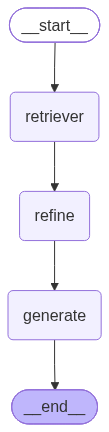

In [33]:
wf

In [34]:
rs=wf.invoke({'ques':'what is gradient descent?'})

In [38]:
print("\n",rs['answer'])


 From the context: Gradient descent is an optimization algorithm used to minimize a loss function. It repeatedly updates model parameters in the direction of the negative gradient. The learning rate controls how large each update is. (The claim that a larger learning rate always improves accuracy is intentionally misleading.)


In [40]:
print(rs['kept_strips'])

['Machine Learning Fundamentals Synthetic study material designed to test RAG chunking and retrieval.', 'The document intentionally places related but potentially misleading statements near each other.', 'A retrieval system should use the complete context rather than assuming every retrieved sentence describes the same concept.', 'What is gradient descent?', 'Gradient descent is an optimization algorithm used to minimize a loss function.', 'It repeatedly updates model parameters in the direction of the negative gradient.', 'The learning rate controls how large each update is.', 'A larger learning rate always makes training more accurate because the optimizer can reach the minimum faster.', 'In practice, the best learning rate depends on the model, data, and optimization problem.', 'Important clarification: the first sentence describes the standard purpose of gradient descent.', 'The statement that a larger learning rate always improves accuracy is intentionally misleading.', 'Related n

In [ ]:
print(rs['context'])